# LAB 06 — Attention Mechanism (experiments)

Thứ tự: kiểm chứng bài tính tay → Exp 1–2 (query giả lập trên Word2Vec) → scaling / temperature → Exp 4 (IMDb: LSTM vs self-attention) → Exp 3 (attention visualization) → Exp 5 (chi phí O(T²)) → application → error analysis.

- **Core implementation:** `attention_numpy.py` (NumPy). Mô hình PyTorch ở Exp 4 tự viết attention bằng phép nhân ma trận + softmax, **không** dùng `torch.nn.MultiheadAttention`.
- **Dữ liệu IMDb và cấu hình train giống LAB 05:** vocabulary 25 000 từ, embedding 100 chiều train từ đầu, max_length 200 (giữ phần đầu), batch 64, Adam lr 1e-3, 6 epochs, clip 1.0, dropout 0.3, chọn epoch có validation loss thấp nhất.

In [1]:
import os, warnings
os.makedirs("images", exist_ok=True)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"      # để cuBLAS/cuDNN (LSTM) chạy lại ra cùng kết quả
warnings.filterwarnings("ignore")
import re, time, copy, random, gzip, hashlib, logging
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from scipy.stats import spearmanr
from datasets import load_dataset
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import attention_numpy as att

logging.getLogger("gensim").setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 200)
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
results = []
def log(experiment, setting, metric, value):
    results.append({"experiment": experiment, "setting": setting, "metric": metric, "value": value})

Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


## Kiểm chứng bài tính tay (`calculations.md`) bằng `attention_numpy.py`

PASS  test_softmax_basic
PASS  test_softmax_stability
PASS  test_temperature_and_entropy
PASS  test_bai1_to_bai4
PASS  test_scaling_exercise
PASS  test_self_attention_exercise
PASS  test_mask
PASS  test_against_torch
8/8 tests passed

Bài 0: softmax([2, 1, 0]) = [0.6652 0.2447 0.09  ]
Bài 1: s = K q = [1. 2. 3.]
Bài 2: softmax([1, 2, 3]) = [0.09   0.2447 0.6652] | Σ = 0.9999999999999999
Bài 3: c = [1.5 1.6]
Bài 4 (dot-product): scores = [1. 0. 1.], α = [0.4223 0.1554 0.4223], c = [1.267 0.733]
Bài 4 (scaled): scores = [0.7071 0.     0.7071], α = [0.4011 0.1978 0.4011], c = [1.2033 0.7967]

Bài 5–6: scaling và temperature với QKᵀ = [4, 2, 0]


,case,scores,softmax,max weight,entropy
0,không scaling,"[4.0, 2.0, 0.0]","[0.8668, 0.1173, 0.0159]",0.8668,0.4411
1,scaling ÷ √4,"[2.0, 1.0, 0.0]","[0.6652, 0.2447, 0.09]",0.6652,0.8324
2,temperature T = 0.5,"[8.0, 4.0, 0.0]","[0.9817, 0.018, 0.0003]",0.9817,0.0930
3,temperature T = 1.0,"[4.0, 2.0, 0.0]","[0.8668, 0.1173, 0.0159]",0.8668,0.4411
4,temperature T = 2.0,"[2.0, 1.0, 0.0]","[0.6652, 0.2447, 0.09]",0.6652,0.8324


Bài 7: naive softmax([1000, 1001, 1002]) = [nan nan nan]
       stable softmax([1000, 1001, 1002]) = [0.09   0.2447 0.6652]

Bài 8 — self-attention (X, W_Q, W_K, W_V tự chọn, xem calculations.md)
Q = [[1.0, 0.0], [1.0, 1.0], [2.0, 1.0]]
K = [[0.0, 1.0], [1.0, 0.0], [1.0, 1.0]]
V = [[1.0, 0.0], [0.0, 2.0], [1.0, 2.0]]


QKᵀ            QKᵀ/√2                 A = softmax                
        I like cats       I    like    cats           I    like    cats
I     0.0  1.0  1.0  0.0000  0.7071  0.7071      0.1978  0.4011  0.4011
like  1.0  1.0  2.0  0.7071  0.7071  1.4142      0.2483  0.2483  0.5035
cats  1.0  2.0  3.0  0.7071  1.4142  2.1213      0.1400  0.2840  0.5760

,z1,z2
I,0.5989,1.6044
like,0.7517,1.5035
cats,0.7160,1.7199


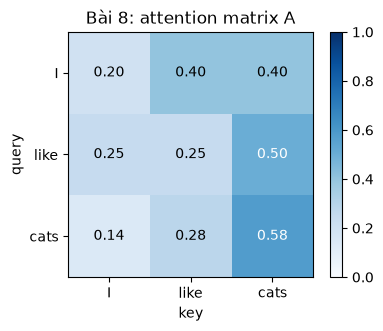

In [2]:
att.run_tests()
np.set_printoptions(precision=4, suppress=True)
print("\nBài 0: softmax([2, 1, 0]) =", att.softmax([2, 1, 0]))
s, _, _ = att.scaled_dot_product_attention(att.BAI1["q"], att.BAI1["K"], np.eye(3), scale=False)
print("Bài 1: s = K q =", s)
a = att.softmax([1, 2, 3]); print("Bài 2: softmax([1, 2, 3]) =", a, "| Σ =", a.sum())
print("Bài 3: c =", np.asarray(att.BAI3["alpha"]) @ np.asarray(att.BAI3["V"], float))
for scale in (False, True):
    s, a, c = att.scaled_dot_product_attention(att.BAI4["q"], att.BAI4["K"], att.BAI4["V"], scale=scale)
    print(f"Bài 4 ({'scaled' if scale else 'dot-product'}): scores = {s}, α = {a}, c = {c}")
rows = []
for name, sv in [("không scaling", np.array([4., 2., 0.])), ("scaling ÷ √4", np.array([4., 2., 0.]) / 2)]:
    p = att.softmax(sv); rows.append({"case": name, "scores": sv, "softmax": p.round(4), "max weight": p.max(), "entropy": att.entropy(p)})
for T in (0.5, 1.0, 2.0):
    p = att.softmax([4, 2, 0], temperature=T)
    rows.append({"case": f"temperature T = {T}", "scores": np.array([4., 2., 0.]) / T, "softmax": p.round(4), "max weight": p.max(), "entropy": att.entropy(p)})
print("\nBài 5–6: scaling và temperature với QKᵀ = [4, 2, 0]"); display(pd.DataFrame(rows).round(4))
with np.errstate(over="ignore", invalid="ignore"):
    print("Bài 7: naive softmax([1000, 1001, 1002]) =", att.naive_softmax([1000, 1001, 1002]))
print("       stable softmax([1000, 1001, 1002]) =", att.softmax([1000, 1001, 1002]))
sa = att.self_attention(att.SELF_ATT["X"], att.SELF_ATT["W_Q"], att.SELF_ATT["W_K"], att.SELF_ATT["W_V"])
toks3 = att.SELF_ATT["tokens"]
print("\nBài 8 — self-attention (X, W_Q, W_K, W_V tự chọn, xem calculations.md)")
for k in ("Q", "K", "V"):
    print(f"{k} =", sa[k].tolist())
display(pd.concat({"QKᵀ": pd.DataFrame(sa["QK^T"], index=toks3, columns=toks3), "QKᵀ/√2": pd.DataFrame(sa["scores"], index=toks3, columns=toks3),
                   "A = softmax": pd.DataFrame(sa["weights"], index=toks3, columns=toks3)}, axis=1).round(4))
display(pd.DataFrame(sa["output"], index=toks3, columns=["z1", "z2"]).round(4))
fig, ax = plt.subplots(figsize=(4.2, 3.4))
im = ax.imshow(sa["weights"], cmap="Blues", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(sa["weights"]):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
ax.set_xticks(range(3), toks3); ax.set_yticks(range(3), toks3); ax.set_xlabel("key"); ax.set_ylabel("query")
ax.set_title("Bài 8: attention matrix A"); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig("images/self_attention_exercise.png", dpi=150); plt.show()

## Experiment 1 — Attention distribution với query giả lập

Key/Value = word vector của từng token (Word2Vec CBOW 100 chiều, train lại trên text8 như LAB 03, **1 luồng + hàm hash cố định** để chạy lại ra cùng kết quả). Mỗi vector được chuẩn hóa về độ dài √d<sub>k</sub> = 10, tức mỗi thành phần có độ lớn khoảng 1 (đúng giả định của scaled dot-product); khi đó score = q·k/√d<sub>k</sub> = 10·cos(q, k).

**Query giả lập A (sentiment)** = trung bình vector của *excellent, terrible, wonderful, awful, great, bad*. Không từ nào trong số này có mặt trong câu, nên attention không "khớp chữ" mà khớp theo nghĩa trong không gian vector.

In [3]:
words = gzip.open(os.path.expanduser("~/gensim-data/text8/text8.gz"), "rt").read().split()
text8 = [words[i:i + 10000] for i in range(0, len(words), 10000)]
def md5_hash(s):
    return int(hashlib.md5(s.encode()).hexdigest()[:8], 16)
t0 = time.time()
w2v = Word2Vec(text8, vector_size=100, window=5, min_count=5, sg=0, epochs=5, workers=1, seed=SEED, hashfxn=md5_hash)
wv, D = w2v.wv, w2v.wv.vector_size
print(f"Word2Vec CBOW trên text8: {len(words):,} token, vocab {len(wv):,}, {time.time() - t0:.0f}s")
def std_vec(w):
    v = wv[w]; return v / np.linalg.norm(v) * np.sqrt(D)
def make_query(ws):
    q = np.mean([std_vec(w) for w in ws], axis=0); return q / np.linalg.norm(q) * np.sqrt(D)

SENT_DISPLAY = "The movie was surprisingly good despite a very slow beginning".split()
sent = [w.lower() for w in SENT_DISPLAY]
K1 = np.vstack([std_vec(w) for w in sent])
QUERIES = {"A — sentiment": ["excellent", "terrible", "wonderful", "awful", "great", "bad"],
           "B — topic (phim ảnh)": ["film", "cinema", "actor", "director", "scene", "drama"],
           "C — thời gian / thứ tự": ["end", "start", "early", "later", "finally", "first"]}
assert not any(w in sent for ws in QUERIES.values() for w in ws)
qA = make_query(QUERIES["A — sentiment"])
scoresA, alphaA, _ = att.scaled_dot_product_attention(qA, K1, K1)
exp1 = pd.DataFrame({"Token": SENT_DISPLAY, "Score": scoresA, "Attention": alphaA})
display(exp1.round(3))
print(f"max weight = {alphaA.max():.3f} ({SENT_DISPLAY[alphaA.argmax()]}), entropy = {att.entropy(alphaA):.3f} (đều: ln 10 = {np.log(10):.3f})")
for _, r in exp1.iterrows():
    log("exp1 query A (sentiment)", r.Token, "attention", r.Attention)

Word2Vec CBOW trên text8: 17,005,207 token, vocab 71,290, 89s


,Token,Score,Attention
0,The,-0.026,0.002
1,movie,3.470,0.051
2,was,-0.968,0.001
3,surprisingly,1.745,0.009
4,good,6.344,0.899
5,despite,0.793,0.003
6,a,0.782,0.003
7,very,1.374,0.006
8,slow,2.680,0.023
9,beginning,0.497,0.003


max weight = 0.899 (good), entropy = 0.477 (đều: ln 10 = 2.303)


## Experiment 2 — Thay đổi query (cùng một câu)

A — sentiment            | top-3: [('good', np.float64(0.899)), ('movie', np.float64(0.051)), ('slow', np.float64(0.023))] | entropy 0.477
B — topic (phim ảnh)     | top-3: [('movie', np.float64(0.994)), ('beginning', np.float64(0.001)), ('was', np.float64(0.001))] | entropy 0.048
C — thời gian / thứ tự   | top-3: [('beginning', np.float64(0.954)), ('slow', np.float64(0.014)), ('The', np.float64(0.013))] | entropy 0.269


,A — sentiment,B — topic (phim ảnh),C — thời gian / thứ tự
The,0.002,0.000,0.013
movie,0.051,0.994,0.003
was,0.001,0.001,0.006
surprisingly,0.009,0.001,0.000
good,0.899,0.001,0.002
despite,0.003,0.001,0.002
a,0.003,0.000,0.005
very,0.006,0.001,0.001
slow,0.023,0.000,0.014
beginning,0.003,0.001,0.954


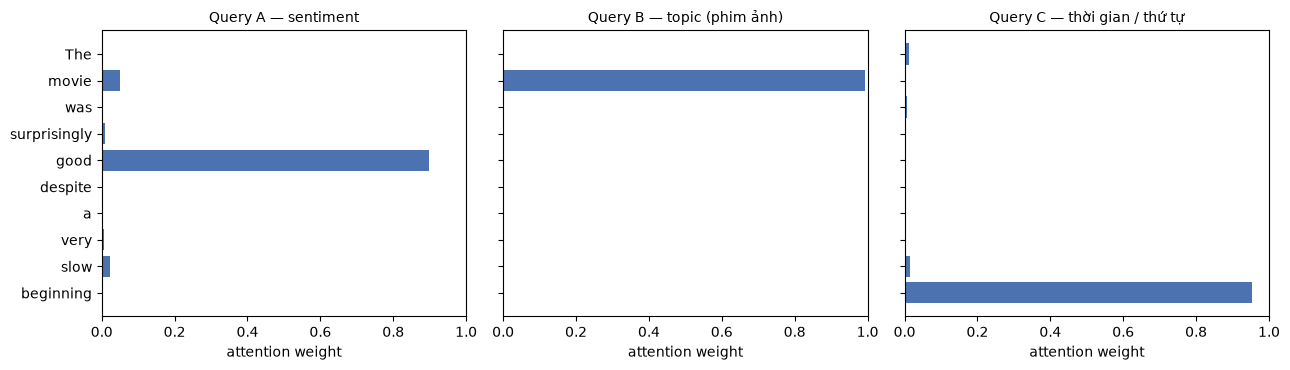

In [4]:
exp2 = {}
for name, ws in QUERIES.items():
    s, a, _ = att.scaled_dot_product_attention(make_query(ws), K1, K1)
    exp2[name] = a
    top = np.argsort(-a)[:3]
    print(f"{name:24s} | top-3: {[(SENT_DISPLAY[i], round(a[i], 3)) for i in top]} | entropy {att.entropy(a):.3f}")
    log("exp2 query", name, "top token", SENT_DISPLAY[top[0]]); log("exp2 query", name, "max weight", a.max()); log("exp2 query", name, "entropy", att.entropy(a))
display(pd.DataFrame(exp2, index=SENT_DISPLAY).round(3))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a_, (name, a) in zip(ax, exp2.items()):
    a_.barh(range(len(sent)), a, color="#4c72b0"); a_.set_title(f"Query {name}", fontsize=10); a_.set_xlim(0, 1); a_.set_xlabel("attention weight")
ax[0].set_yticks(range(len(sent)), SENT_DISPLAY); ax[0].invert_yaxis()
plt.tight_layout(); plt.savefig("images/attention_queries.png", dpi=150); plt.show()

## Scaling và temperature
(a) Temperature T = 0.5 / 1 / 2 trên score của Exp 1. (b) Vì sao chia √d<sub>k</sub>: q, k ~ N(0, 1) ngẫu nhiên, 10 key, 2 000 lần thử cho mỗi d<sub>k</sub>. "‖J‖" = chuẩn Frobenius của Jacobian softmax (diag(α) − ααᵀ), đo độ lớn gradient đi qua softmax.

,Max weight,Entropy,Token max,weight 'movie',weight 'slow',Nhận xét
Temperature,,,,,,
0.5,0.9960,0.0289,good,0.0032,0.0007,tập trung hơn
1.0,0.8992,0.4771,good,0.0508,0.0230,gốc
2.0,0.5475,1.5884,good,0.1301,0.0877,phẳng hơn


,d_k,scaled,std(q·k),mean max weight,mean entropy,mean ‖J‖ softmax
0,4,False,2.0248,0.4971,1.4248,0.3349
1,4,True,2.0248,0.3081,1.9404,0.3401
2,16,False,4.0365,0.7318,0.7315,0.2628
3,16,True,4.0365,0.3187,1.9234,0.3468
4,64,False,7.9812,0.8713,0.3292,0.1542
5,64,True,7.9812,0.3187,1.9292,0.3481
6,256,False,16.0440,0.9271,0.1762,0.0942
7,256,True,16.0440,0.3175,1.9265,0.3470
8,1024,False,32.0186,0.9656,0.0825,0.0474
9,1024,True,32.0186,0.3233,1.9188,0.3472


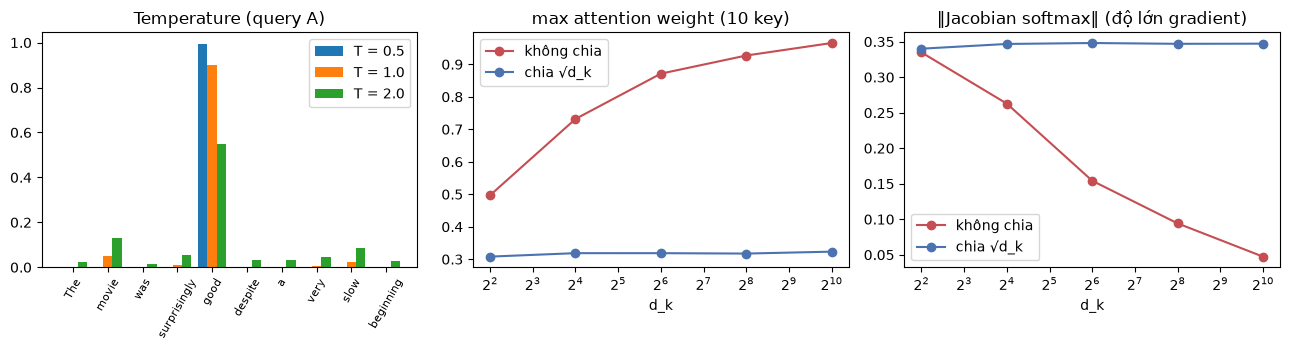

In [5]:
temp_rows = []
for T in (0.5, 1.0, 2.0):
    p = att.softmax(scoresA, temperature=T)
    note = {0.5: "tập trung hơn", 1.0: "gốc", 2.0: "phẳng hơn"}[T]
    temp_rows.append({"Temperature": T, "Max weight": p.max(), "Entropy": att.entropy(p), "Token max": SENT_DISPLAY[p.argmax()],
                      "weight 'movie'": p[1], "weight 'slow'": p[8], "Nhận xét": note})
    log("temperature (Exp 1 scores)", f"T={T}", "max weight", p.max()); log("temperature (Exp 1 scores)", f"T={T}", "entropy", att.entropy(p))
temp_table = pd.DataFrame(temp_rows).set_index("Temperature")
display(temp_table.round(4))

def softmax_jac_norm(p):
    s2 = (p ** 2).sum(-1)
    return np.sqrt(np.maximum(s2 - 2 * (p ** 3).sum(-1) + s2 ** 2, 0.0))
rng = np.random.default_rng(SEED)
dk_rows = []
for dk in (4, 16, 64, 256, 1024):
    q = rng.standard_normal((2000, dk)); Kr = rng.standard_normal((2000, 10, dk))
    raw = np.einsum("td,tkd->tk", q, Kr)
    for scaled in (False, True):
        p = att.softmax(raw / np.sqrt(dk) if scaled else raw, axis=-1)
        dk_rows.append({"d_k": dk, "scaled": scaled, "std(q·k)": raw.std(), "mean max weight": p.max(-1).mean(),
                        "mean entropy": att.entropy(p).mean(), "mean ‖J‖ softmax": softmax_jac_norm(p).mean()})
dk_table = pd.DataFrame(dk_rows)
display(dk_table.round(4))
for _, r in dk_table.iterrows():
    for m in ("mean max weight", "mean entropy", "mean ‖J‖ softmax"):
        log("scaling vs d_k", f"d_k={r.d_k} {'scaled' if r.scaled else 'unscaled'}", m, r[m])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
x = np.arange(len(SENT_DISPLAY))
for i, T in enumerate((0.5, 1.0, 2.0)):
    ax[0].bar(x + (i - 1) * 0.27, att.softmax(scoresA, temperature=T), width=0.27, label=f"T = {T}")
ax[0].set_xticks(x, SENT_DISPLAY, rotation=60, fontsize=8); ax[0].set_title("Temperature (query A)"); ax[0].legend()
for scaled, c in ((False, "#c44e52"), (True, "#4c72b0")):
    g = dk_table[dk_table.scaled == scaled]
    lbl = "chia √d_k" if scaled else "không chia"
    ax[1].plot(g.d_k, g["mean max weight"], marker="o", color=c, label=lbl)
    ax[2].plot(g.d_k, g["mean ‖J‖ softmax"], marker="o", color=c, label=lbl)
for a_, t in ((ax[1], "max attention weight (10 key)"), (ax[2], "‖Jacobian softmax‖ (độ lớn gradient)")):
    a_.set_xscale("log", base=2); a_.set_xlabel("d_k"); a_.set_title(t); a_.legend()
plt.tight_layout(); plt.savefig("images/scaling_temperature.png", dpi=150); plt.show()

## Experiment 4 — IMDb: LSTM (final hidden state) vs Self-Attention (context vector)

- **LSTM:** Embedding → LSTM (hidden 128) → h<sub>T</sub> → Linear (giống LAB 05).
- **Self-Attention** (model chính, theo pipeline mục 26): Embedding X → Q = XW<sub>Q</sub>, K = XW<sub>K</sub>, V = XW<sub>V</sub> (d = 128) → H = softmax(QKᵀ/√d)V (mask padding) → **context vector c = Attention(u, K, H) = Σ<sub>t</sub> β<sub>t</sub> h<sub>t</sub>**, β = softmax(K·u/√d), với u là một **query học được** ("review này nói gì về sentiment?") → Linear. Không có thông tin vị trí.
- **Self-Attention (pooling trên H)** — ablation: giống model chính nhưng điểm pooling tính trên H thay vì K: β = softmax(H·u/√d). Phiên bản đầu tiên em làm theo cách này và thấy β gần như đều (xem bảng "β có tập trung không?").
- **Self-Attention + positional embedding** (thử thêm, xem trước LAB 07): giống model chính nhưng cộng thêm embedding vị trí học được vào X.

In [6]:
ds = load_dataset("stanfordnlp/imdb")
train_raw, test_df = ds["train"].to_pandas(), ds["test"].to_pandas()
_BR, _NON, _SP = re.compile(r"<br\s*/?>", re.I), re.compile(r"[^a-z0-9'\s]"), re.compile(r"\s+")
def clean_text(t):
    return _SP.sub(" ", _NON.sub(" ", _BR.sub(" ", str(t).lower()))).strip()
def tokenize(t):
    return clean_text(t).split()
train_dedup = train_raw.drop_duplicates("text").reset_index(drop=True)
tr_df, va_df = train_test_split(train_dedup, test_size=0.2, stratify=train_dedup.label, random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
tok = {k: [tokenize(t) for t in d.text] for k, d in [("train", tr_df), ("val", va_df), ("test", test_df)]}
y = {"train": tr_df.label.values, "val": va_df.label.values, "test": test_df.label.values}
counts = Counter(w for t in tok["train"] for w in t)
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(25000)]
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK, MAX_LEN = 0, 1, 200
def encode(tokens, max_len=MAX_LEN):
    return ([stoi.get(w, UNK) for w in tokens] or [UNK])[:max_len]
def to_tensor(tok_lists, max_len=MAX_LEN):
    seqs = [encode(t, max_len) for t in tok_lists]
    X = np.zeros((len(seqs), max_len), dtype=np.int64)
    for i, s in enumerate(seqs):
        X[i, :len(s)] = s
    return torch.from_numpy(X), torch.tensor([len(s) for s in seqs])
data = {k: to_tensor(tok[k]) for k in ("train", "val", "test")}
print(f"train {len(tr_df)} / validation {len(va_df)} / test {len(test_df)} | vocabulary {len(itos):,}")

train 19923 / validation 4981 / test 25000 | vocabulary 25,002


In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size=len(itos), emb_dim=100, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = nn.LSTM(emb_dim, hidden, batch_first=True)
        self.drop, self.out = nn.Dropout(dropout), nn.Linear(hidden, 1)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(self.emb(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(packed)
        return self.out(self.drop(h[-1])).squeeze(-1)


class SelfAttentionClassifier(nn.Module):
    """Embedding → self-attention (1 head, tự viết) → context = Attention(u, K, H) với query học được u → Linear.
    pool="key": điểm pooling = K·u (key của từng token); pool="hidden": điểm pooling = H·u (ablation)."""
    def __init__(self, vocab_size=len(itos), emb_dim=100, d=128, use_pos=False, max_len=MAX_LEN, dropout=0.3, pool="key"):
        super().__init__()
        self.pool = pool
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.pos = nn.Embedding(max_len, emb_dim) if use_pos else None
        self.W_Q, self.W_K, self.W_V = (nn.Linear(emb_dim, d, bias=False) for _ in range(3))
        self.u = nn.Parameter(torch.randn(d) / d ** 0.5)
        self.drop, self.out, self.d = nn.Dropout(dropout), nn.Linear(d, 1), d

    def forward(self, x, lengths=None, mask=None, return_attn=False):
        m = (x != PAD) if mask is None else mask                         # True = token thật (được attend)
        e = self.emb(x)
        if self.pos is not None:
            e = e + self.pos(torch.arange(x.shape[1], device=x.device))[None]
        Q, K, V = self.W_Q(e), self.W_K(e), self.W_V(e)
        S = Q @ K.transpose(1, 2) / self.d ** 0.5                         # (B, T, T)
        A = torch.softmax(S.masked_fill(~m[:, None, :], float("-inf")), dim=-1)
        H = A @ V                                                         # contextual representations
        P = K if self.pool == "key" else H
        g = (P @ self.u / self.d ** 0.5).masked_fill(~m, float("-inf"))
        beta = torch.softmax(g, dim=-1)                                   # attention pooling weights
        c = (beta.unsqueeze(-1) * H).sum(1)                               # context vector
        logit = self.out(self.drop(c)).squeeze(-1)
        return (logit, A, beta) if return_attn else logit

# Kiểm tra: lớp attention của PyTorch model cho đúng kết quả với hàm NumPy khi dùng cùng trọng số
chk = SelfAttentionClassifier().double().eval()
xs = torch.tensor([[5, 17, 300, 42, 9]])
with torch.no_grad():
    e = chk.emb(xs)[0].numpy()
    _, A_t, _ = chk(xs, return_attn=True)
ref = att.self_attention(e, chk.W_Q.weight.detach().numpy().T, chk.W_K.weight.detach().numpy().T, chk.W_V.weight.detach().numpy().T)
print("max |A_pytorch − A_numpy| =", float(np.abs(A_t[0].numpy() - ref["weights"]).max()))

max |A_pytorch − A_numpy| = 8.326672684688674e-17


In [8]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}

def batches(X, lens, yv, bs, shuffle):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j].to(device), lens[j].to(device), (torch.as_tensor(yv[j.numpy()], dtype=torch.float32).to(device) if yv is not None else None)

@torch.no_grad()
def predict_logits(model, X, lens, bs=512):
    model.eval()
    return torch.cat([model(xb, lb).float().cpu() for xb, lb, _ in batches(X, lens, None, bs, False)])

store, curves, model_rows = {}, {}, []
def run(name, make_model, epochs=6, bs=64, lr=1e-3):
    set_seed()
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.BCEWithLogitsLoss()
    hist, best, best_state = [], (np.inf, 0), None
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, lb, yb in batches(*data["train"], y["train"], bs, True):
            opt.zero_grad(); loss = lossf(model(xb, lb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(yb); n += len(yb)
        logits = predict_logits(model, *data["val"])
        vloss = float(nn.functional.binary_cross_entropy_with_logits(logits, torch.tensor(y["val"], dtype=torch.float32)))
        hist.append({"epoch": ep, "train loss": tot / n, "val loss": vloss, "val acc": accuracy_score(y["val"], logits.numpy() > 0)})
        if vloss < best[0]:
            best, best_state = (vloss, ep), copy.deepcopy(model.state_dict())
    if device.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan
    model.load_state_dict(best_state)
    prob = torch.sigmoid(predict_logits(model, *data["test"])).numpy()
    row = {"model": name, "params": sum(p.numel() for p in model.parameters()), "best epoch": best[1], "train time (s)": dt,
           "time / epoch (s)": dt / epochs, "peak GPU mem (MB)": mem, "best val loss": best[0], **metrics(y["test"], prob > 0.5)}
    model_rows.append(row); curves[name] = pd.DataFrame(hist); store[name] = {"model": model.eval(), "prob": prob}
    for k in ("params", "best epoch", "train time (s)", "peak GPU mem (MB)", "best val loss", "accuracy", "precision", "recall", "f1"):
        log("exp4 IMDb test", name, k, row[k])
    print(f"{name:34s} | best epoch {best[1]} | val loss {best[0]:.4f} | test acc {row['accuracy']:.4f} F1 {row['f1']:.4f} | {dt:.1f}s")

run("LSTM", LSTMClassifier)
run("Self-Attention (pooling trên H)", lambda: SelfAttentionClassifier(pool="hidden"))
run("Self-Attention", SelfAttentionClassifier)
run("Self-Attention + positional emb.", lambda: SelfAttentionClassifier(use_pos=True))
exp4 = pd.DataFrame(model_rows).set_index("model")
display(exp4[["accuracy", "precision", "recall", "f1", "train time (s)", "time / epoch (s)", "params", "peak GPU mem (MB)", "best epoch"]].round(4))

LSTM                               | best epoch 4 | val loss 0.4044 | test acc 0.8264 F1 0.8177 | 42.1s


Self-Attention (pooling trên H)    | best epoch 3 | val loss 0.3604 | test acc 0.8318 F1 0.8222 | 12.7s


Self-Attention                     | best epoch 3 | val loss 0.3575 | test acc 0.8351 F1 0.8259 | 12.5s


Self-Attention + positional emb.   | best epoch 2 | val loss 0.3717 | test acc 0.8304 F1 0.8278 | 12.9s


,accuracy,precision,recall,f1,train time (s),time / epoch (s),params,peak GPU mem (MB),best epoch
model,,,,,,,,,
LSTM,0.8264,0.8612,0.7783,0.8177,42.1175,7.0196,2618089,361.5190,4
Self-Attention (pooling trên H),0.8318,0.8718,0.7779,0.8222,12.6733,2.1122,2538857,581.5229,3
Self-Attention,0.8351,0.8746,0.7824,0.8259,12.5054,2.0842,2538857,600.8940,3
Self-Attention + positional emb.,0.8304,0.8409,0.8150,0.8278,12.9205,2.1534,2558857,620.6484,2


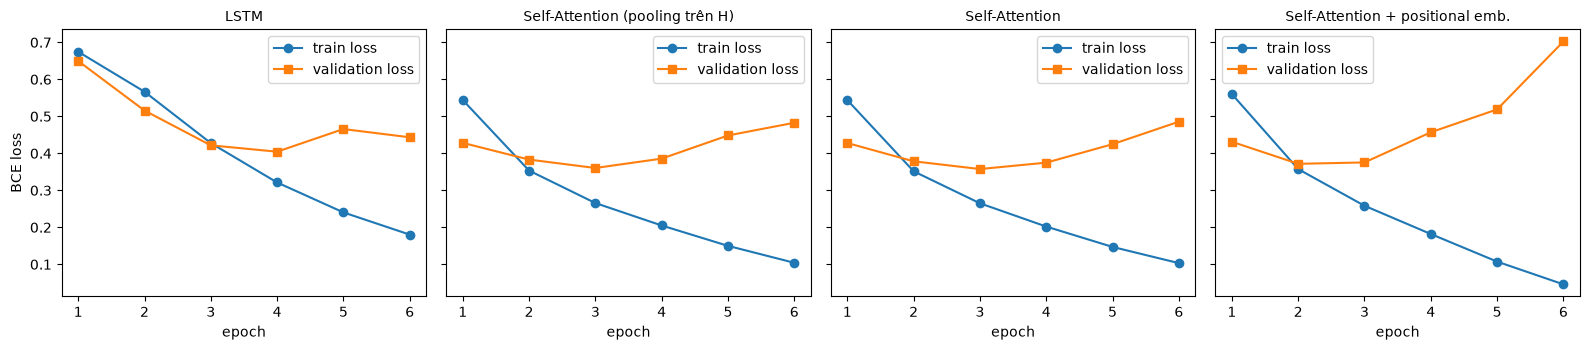

LSTM                  Self-Attention (pooling trên H)           \
      train loss val loss val acc                      train loss val loss   
epoch                                                                        
1         0.6746   0.6496  0.6151                          0.5441   0.4283   
2         0.5666   0.5157  0.7547                          0.3534   0.3831   
3         0.4277   0.4217  0.8081                          0.2656   0.3604   
4         0.3212   0.4044  0.8384                          0.2050   0.3857   
5         0.2403   0.4657  0.8071                          0.1499   0.4483   
6         0.1803   0.4433  0.8472                          0.1041   0.4826   

              Self-Attention                   \
      val acc     train loss val loss val acc   
epoch                                           
1      0.7974         0.5440   0.4278  0.7914   
2      0.8320         0.3515   0.3785  0.8285   
3      0.8398         0.2650   0.3575  0.8422   
4      0.8434         0.2021   0.3748  0.8478   
5      0.8448         0.1470   0.4247  0.8510   
6      0.8414         0.1032   0.4856  0.8432   

      Self-Attention + positional emb.                   
                            train loss val loss val acc  
epoch                                                    
1                               0.5602   0.4313  0.7978  
2                               0.3574   0.3717  0.8283  
3                               0.2583   0.3754  0.8376  
4                               0.1819   0.4569  0.8259  
5                               0.1073   0.5188  0.8354  
6                               0.0459   0.7024  0.8356

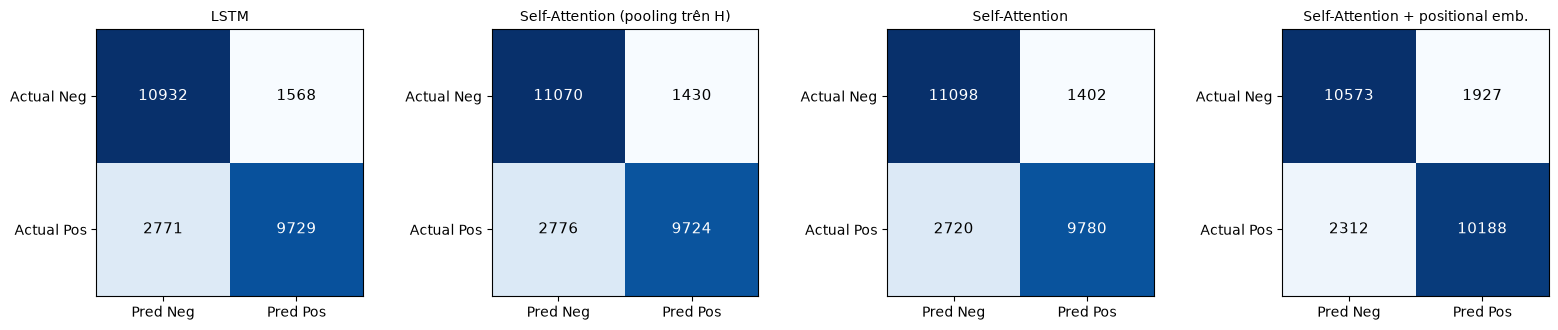

β có tập trung không? (entropy β / log L = 1 nghĩa là đều tuyệt đối; 10% token cao nhất nhận 10% khối lượng nếu đều)


,β max trung bình,β đều (1/L) trung bình,entropy β / log L,khối lượng β trên 10% token cao nhất
model,,,,
Self-Attention (pooling trên H),0.0098,0.0073,0.9977,0.1195
Self-Attention,0.0270,0.0073,0.9684,0.2189
Self-Attention + positional emb.,0.0145,0.0073,0.9918,0.1525


In [9]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for a_, name in zip(ax, curves):
    cv = curves[name]
    a_.plot(cv.epoch, cv["train loss"], marker="o", label="train loss"); a_.plot(cv.epoch, cv["val loss"], marker="s", label="validation loss")
    a_.set_title(name, fontsize=10); a_.set_xlabel("epoch"); a_.legend()
ax[0].set_ylabel("BCE loss"); plt.tight_layout(); plt.savefig("images/learning_curves.png", dpi=150); plt.show()
display(pd.concat({n: c.set_index("epoch") for n, c in curves.items()}, axis=1).round(4))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a_, name in zip(ax, store):
    cm = confusion_matrix(y["test"], store[name]["prob"] > 0.5)
    a_.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a_.text(j, i, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    a_.set_xticks([0, 1], ["Pred Neg", "Pred Pos"]); a_.set_yticks([0, 1], ["Actual Neg", "Actual Pos"]); a_.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=150); plt.show()

# β có tập trung không? (2 000 review test đầu tiên)
conc = []
with torch.no_grad():
    Xs, Ls = data["test"][0][:2000].to(device), data["test"][1][:2000].numpy()
    for name in [n for n in store if n.startswith("Self-Attention")]:
        _, _, b = store[name]["model"](Xs, return_attn=True)
        b = b.cpu().numpy()
        conc.append({"model": name, "β max trung bình": np.mean([b[i, :Ls[i]].max() for i in range(len(Ls))]),
                     "β đều (1/L) trung bình": np.mean(1 / Ls),
                     "entropy β / log L": np.mean([att.entropy(b[i, :Ls[i]]) / np.log(Ls[i]) for i in range(len(Ls)) if Ls[i] > 1]),
                     "khối lượng β trên 10% token cao nhất": np.mean([np.sort(b[i, :Ls[i]])[::-1][:max(1, Ls[i] // 10)].sum() for i in range(len(Ls))])})
conc = pd.DataFrame(conc).set_index("model")
print("β có tập trung không? (entropy β / log L = 1 nghĩa là đều tuyệt đối; 10% token cao nhất nhận 10% khối lượng nếu đều)")
display(conc.round(4))
for name, r in conc.iterrows():
    for k, v in r.items():
        log("β concentration (2000 test reviews)", name, k, v)

### Representation khác nhau ở đâu? Kiểm tra độ nhạy với thứ tự từ
Đảo thứ tự từ trong câu: self-attention không có thông tin vị trí nên QKᵀ, softmax và tổng có trọng số chỉ hoán vị theo → context vector **không đổi**. LSTM đọc tuần tự nên h<sub>T</sub> thay đổi.

In [10]:
@torch.no_grad()
def prob_of(name, texts):
    X, l = to_tensor([tokenize(t) for t in texts])
    return torch.sigmoid(predict_logits(store[name]["model"], X, l)).numpy()

ORDER = [("I do not like this movie", "not I do like this movie"),
         ("the movie was not good it was bad", "the movie was bad it was not good"),
         ("dog bites man", "man bites dog"),
         ("I expected it to be bad but it was actually wonderful", "I expected it to be wonderful but it was actually bad")]
order_rows = []
for a_txt, b_txt in ORDER:
    for name in store:
        pa, pb = prob_of(name, [a_txt, b_txt])
        order_rows.append({"model": name, "câu gốc": a_txt, "câu đảo thứ tự": b_txt, "P(pos) gốc": pa, "P(pos) đảo": pb, "|Δ|": abs(pa - pb)})
order_df = pd.DataFrame(order_rows)
display(order_df.round(4))
for name, g in order_df.groupby("model", sort=False):
    print(f"{name:34s} max |ΔP| khi đảo thứ tự = {g['|Δ|'].max():.2e}")
    log("order sensitivity", name, "max |ΔP| when reordering", g["|Δ|"].max())

,model,câu gốc,câu đảo thứ tự,P(pos) gốc,P(pos) đảo,|Δ|
0,LSTM,I do not like this movie,not I do like this movie,0.3323,0.3225,0.0099
1,Self-Attention (pooling trên H),I do not like this movie,not I do like this movie,0.0003,0.0003,0.0000
2,Self-Attention,I do not like this movie,not I do like this movie,0.0002,0.0002,0.0000
3,Self-Attention + positional emb.,I do not like this movie,not I do like this movie,0.0000,0.0000,0.0000
4,LSTM,the movie was not good it was bad,the movie was bad it was not good,0.0950,0.1731,0.0782
5,Self-Attention (pooling trên H),the movie was not good it was bad,the movie was bad it was not good,0.1567,0.1567,0.0000
6,Self-Attention,the movie was not good it was bad,the movie was bad it was not good,0.0022,0.0022,0.0000
7,Self-Attention + positional emb.,the movie was not good it was bad,the movie was bad it was not good,0.0012,0.0001,0.0011
8,LSTM,dog bites man,man bites dog,0.4241,0.4250,0.0008
9,Self-Attention (pooling trên H),dog bites man,man bites dog,0.9681,0.9681,0.0000


LSTM                               max |ΔP| khi đảo thứ tự = 3.82e-01
Self-Attention (pooling trên H)    max |ΔP| khi đảo thứ tự = 7.45e-08
Self-Attention                     max |ΔP| khi đảo thứ tự = 2.33e-10
Self-Attention + positional emb.   max |ΔP| khi đảo thứ tự = 9.33e-03


## Experiment 3 — Attention visualization
Hai cách nhìn trên cùng hai câu:
1. **Word2Vec, W<sub>Q</sub> = W<sub>K</sub> = W<sub>V</sub> = I** (chưa học gì): score = độ tương đồng giữa hai word vector.
2. **Lớp self-attention của classifier đã train trên IMDb** (model "Self-Attention" ở Exp 4).

'The cat that I adopted yesterday is sleeping': P(pos) = 0.174; β (pooling) = {'the': np.float32(0.035), 'cat': np.float32(0.134), 'that': np.float32(0.14), 'i': np.float32(0.111), 'adopted': np.float32(0.228), 'yesterday': np.float32(0.193), 'is': np.float32(0.04), 'sleeping': np.float32(0.119)}
'The book that I bought yesterday was expensive': P(pos) = 0.620; β (pooling) = {'the': np.float32(0.03), 'book': np.float32(0.151), 'that': np.float32(0.119), 'i': np.float32(0.094), 'bought': np.float32(0.16), 'yesterday': np.float32(0.164), 'was': np.float32(0.124), 'expensive': np.float32(0.157)}


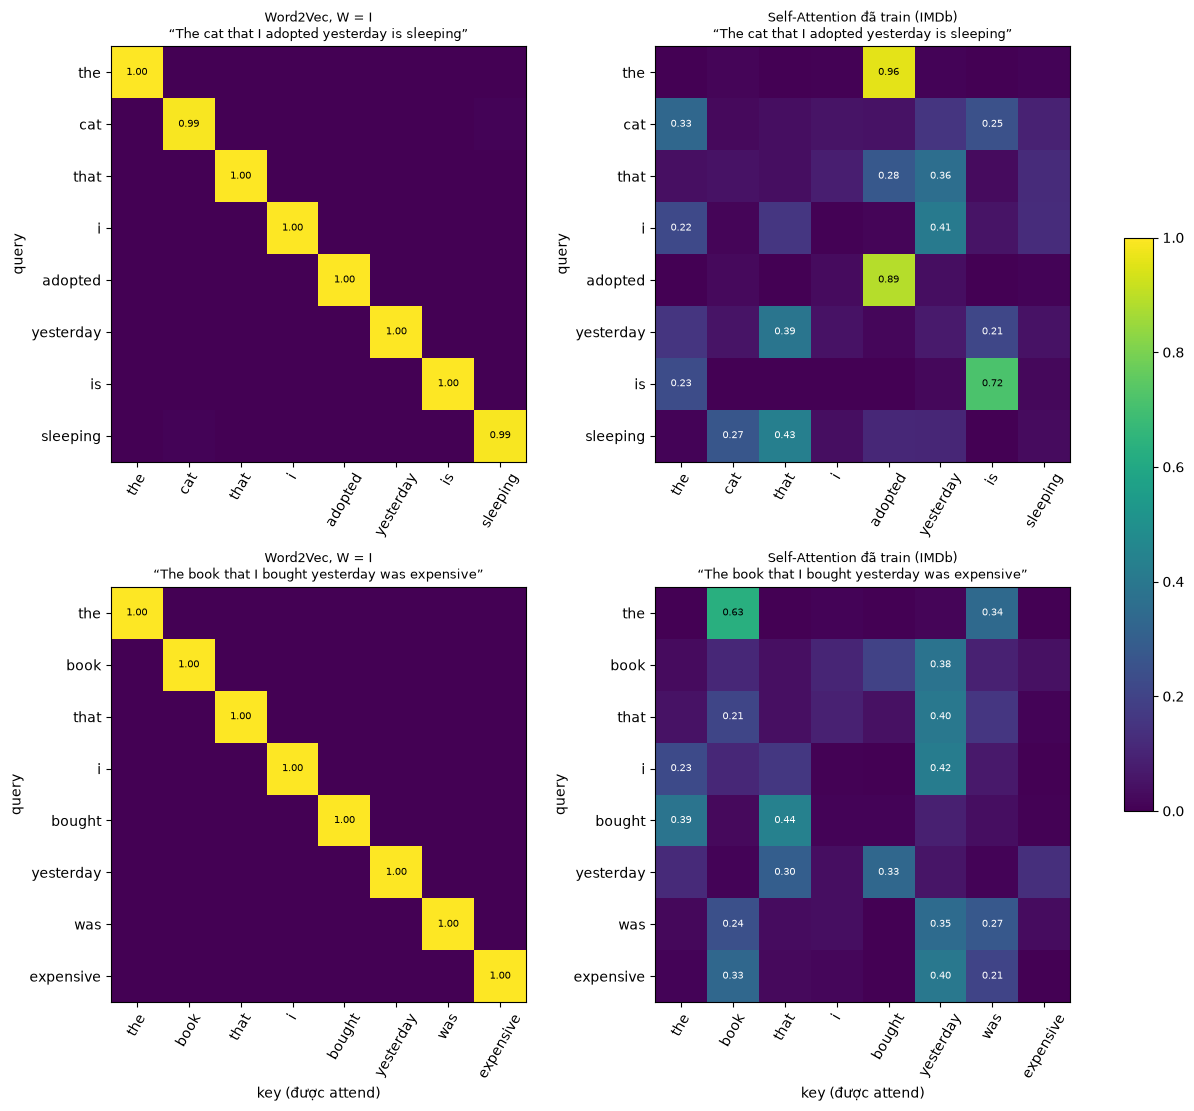

,view,token,self weight,top-1 other,top-2 other,max − min trong hàng
0,"Word2Vec, W = I",cat,0.991,sleeping (0.009),yesterday (0.001),0.991
1,"Word2Vec, W = I",adopted,1.000,the (0.000),is (0.000),1.000
2,"Word2Vec, W = I",sleeping,0.990,cat (0.009),yesterday (0.002),0.990
3,Self-Attention đã train (IMDb),cat,0.025,the (0.333),is (0.249),0.308
4,Self-Attention đã train (IMDb),adopted,0.890,yesterday (0.039),i (0.029),0.890
5,Self-Attention đã train (IMDb),sleeping,0.030,that (0.430),cat (0.268),0.427
6,"Word2Vec, W = I",book,0.999,that (0.000),i (0.000),0.999
7,"Word2Vec, W = I",bought,0.999,expensive (0.000),was (0.000),0.999
8,"Word2Vec, W = I",expensive,0.999,bought (0.000),that (0.000),0.999
9,Self-Attention đã train (IMDb),book,0.110,yesterday (0.381),bought (0.196),0.351


Word2Vec, W = I                  | weight trung bình trên đường chéo (tự chú ý) = 0.998 | entropy trung bình mỗi hàng = 0.016 (đều: ln 8 = 2.079)
Self-Attention đã train (IMDb)   | weight trung bình trên đường chéo (tự chú ý) = 0.142 | entropy trung bình mỗi hàng = 1.319 (đều: ln 8 = 2.079)


In [11]:
SENTS3 = ["The cat that I adopted yesterday is sleeping", "The book that I bought yesterday was expensive"]
@torch.no_grad()
def model_attention(name, text):
    toks = tokenize(text)
    X, l = to_tensor([toks])
    logit, A, beta = store[name]["model"](X.to(device), l.to(device), return_attn=True)
    L = len(toks)
    return toks, A[0, :L, :L].cpu().numpy(), beta[0, :L].cpu().numpy(), float(torch.sigmoid(logit)[0])

views = {}
for s3 in SENTS3:
    toks = tokenize(s3)
    Xw = np.vstack([std_vec(w) for w in toks]); I = np.eye(D)
    views[(s3, "Word2Vec, W = I")] = (toks, att.self_attention(Xw, I, I, I)["weights"])
    t2, A2, b2, p2 = model_attention("Self-Attention", s3)
    views[(s3, "Self-Attention đã train (IMDb)")] = (t2, A2)
    print(f"{s3!r}: P(pos) = {p2:.3f}; β (pooling) = {dict(zip(t2, b2.round(3)))}")
fig, ax = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for k, (a_, ((s3, view), (toks, A))) in enumerate(zip(ax.ravel(), views.items())):
    im = a_.imshow(A, cmap="viridis", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(A):
        if v >= 0.2:
            a_.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="black" if v > 0.6 else "white")
    a_.set_xticks(range(len(toks)), toks, rotation=60); a_.set_yticks(range(len(toks)), toks)
    a_.set_title(f"{view}\n“{s3}”", fontsize=9); a_.set_ylabel("query")
    if k >= 2:
        a_.set_xlabel("key (được attend)")
fig.colorbar(im, ax=ax.ravel().tolist(), shrink=0.6)
plt.savefig("images/attention_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

focus_rows = []
for (s3, view), (toks, A) in views.items():
    for w in ("cat", "adopted", "sleeping", "book", "bought", "expensive"):
        if w in toks:
            i = toks.index(w); order = [j for j in np.argsort(-A[i]) if j != i][:2]
            focus_rows.append({"view": view, "token": w, "self weight": A[i, i], "top-1 other": f"{toks[order[0]]} ({A[i, order[0]]:.3f})",
                               "top-2 other": f"{toks[order[1]]} ({A[i, order[1]]:.3f})", "max − min trong hàng": A[i].max() - A[i].min()})
focus = pd.DataFrame(focus_rows)
display(focus.round(3))
for view in ("Word2Vec, W = I", "Self-Attention đã train (IMDb)"):
    diag = np.mean([np.trace(A) / len(A) for (s3, v), (t, A) in views.items() if v == view])
    ent = np.mean([att.entropy(A).mean() for (s3, v), (t, A) in views.items() if v == view])
    print(f"{view:32s} | weight trung bình trên đường chéo (tự chú ý) = {diag:.3f} | entropy trung bình mỗi hàng = {ent:.3f} (đều: ln 8 = {np.log(8):.3f})")
    log("exp3 visualization", view, "mean self weight", diag); log("exp3 visualization", view, "mean row entropy", ent)

## Experiment 5 — Sequence length và computational cost
(a) Kích thước attention matrix theo lý thuyết. (b) Đo thời gian thật: hàm NumPy (CPU, 1 câu, d<sub>k</sub> = 64) và một bước train (forward + backward, batch 32, GPU) của LSTM vs Self-Attention.

,attention matrix,phần tử,"MB (float32, 1 head, 1 câu)",so với T=10
T,,,,
10,10×10,100,0.000381,1.0
100,100×100,10000,0.038147,100.0
500,500×500,250000,0.953674,2500.0
1000,1000×1000,1000000,3.814697,10000.0
10000,10000×10000,100000000,381.469727,1000000.0


,NumPy time (ms)
T,
10,0.031
100,0.377
500,6.681
1000,27.700
2000,106.667
4000,405.584


ms / train step                peak GPU MB               
model            LSTM Self-Attention        LSTM Self-Attention
T                                                              
50               11.4            3.8       197.1          195.6
100              10.5            3.2       205.5          195.6
200              16.9            4.2       225.9          211.2
400              29.9            8.0       255.6          285.3
800              55.0           22.3       318.9          547.8
1600            101.4           78.1       451.1         1547.2

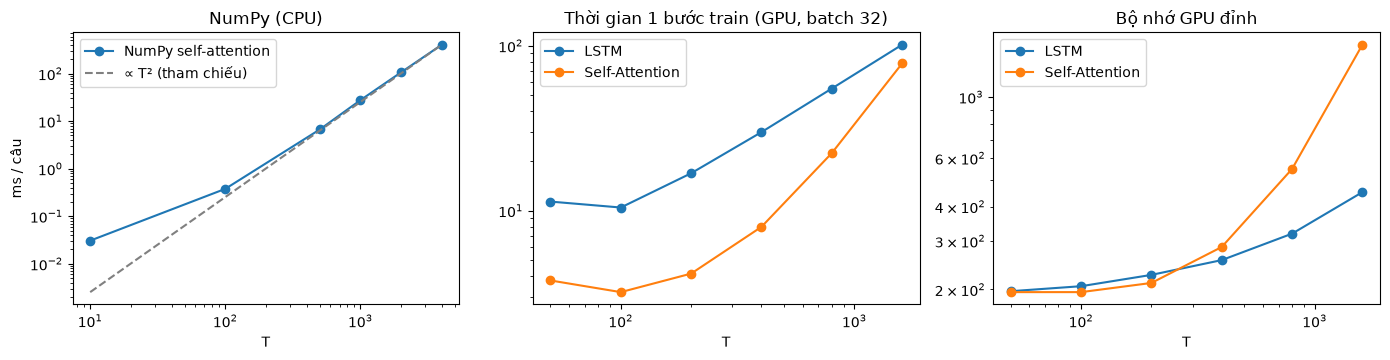

In [12]:
cost_rows = [{"T": T, "attention matrix": f"{T}×{T}", "phần tử": T * T, "MB (float32, 1 head, 1 câu)": T * T * 4 / 2**20, "so với T=10": T * T / 100}
             for T in (10, 100, 500, 1000, 10000)]
display(pd.DataFrame(cost_rows).set_index("T"))
rng = np.random.default_rng(SEED)
np_rows = []
for T in (10, 100, 500, 1000, 2000, 4000):
    Xr = rng.standard_normal((T, 64)); Wr = [rng.standard_normal((64, 64)) / 8 for _ in range(3)]
    reps = 20 if T <= 1000 else 3
    t0 = time.perf_counter()
    for _ in range(reps):
        att.self_attention(Xr, *Wr)
    np_rows.append({"T": T, "NumPy time (ms)": (time.perf_counter() - t0) / reps * 1000})
np_cost = pd.DataFrame(np_rows).set_index("T")
display(np_cost.round(3))

def bench(make_model, T, B=32, reps=5):
    set_seed(); model = make_model().to(device).train()
    opt = torch.optim.Adam(model.parameters()); lossf = nn.BCEWithLogitsLoss()
    x = torch.randint(2, len(itos), (B, T), device=device); l = torch.full((B,), T); yb = torch.randint(0, 2, (B,), device=device).float()
    try:
        for i in range(reps + 2):
            if i == 2:
                torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.perf_counter()
            opt.zero_grad(); lossf(model(x, l), yb).backward(); opt.step()
        torch.cuda.synchronize()
        return (time.perf_counter() - t0) / reps * 1000, torch.cuda.max_memory_allocated() / 2**20
    except torch.cuda.OutOfMemoryError:
        return np.nan, np.nan
    finally:
        del model, opt; torch.cuda.empty_cache()

gpu_rows = []
if device.type == "cuda":
    for mk in (LSTMClassifier, SelfAttentionClassifier):     # warm-up GPU / cuDNN, bỏ kết quả
        bench(mk, 50)
    for T in (50, 100, 200, 400, 800, 1600):
        for name, mk in (("LSTM", LSTMClassifier), ("Self-Attention", SelfAttentionClassifier)):
            ms, mb = bench(mk, T)
            gpu_rows.append({"T": T, "model": name, "ms / train step": ms, "peak GPU MB": mb})
            log("exp5 cost (GPU, batch 32)", f"{name} T={T}", "ms per train step", ms); log("exp5 cost (GPU, batch 32)", f"{name} T={T}", "peak MB", mb)
gpu_cost = pd.DataFrame(gpu_rows)
display(gpu_cost.pivot(index="T", columns="model", values=["ms / train step", "peak GPU MB"]).round(1))
for T, r in np_cost.iterrows():
    log("exp5 cost (NumPy CPU, 1 câu)", f"T={T}", "ms", r["NumPy time (ms)"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
ax[0].loglog(np_cost.index, np_cost["NumPy time (ms)"], marker="o", label="NumPy self-attention")
ref = np_cost["NumPy time (ms)"].iloc[-1] * (np_cost.index / np_cost.index[-1]) ** 2
ax[0].loglog(np_cost.index, ref, "--", color="gray", label="∝ T² (tham chiếu)")
ax[0].set_xlabel("T"); ax[0].set_ylabel("ms / câu"); ax[0].set_title("NumPy (CPU)"); ax[0].legend()
for name, g in gpu_cost.groupby("model"):
    ax[1].loglog(g["T"], g["ms / train step"], marker="o", label=name); ax[2].loglog(g["T"], g["peak GPU MB"], marker="o", label=name)
ax[1].set_title("Thời gian 1 bước train (GPU, batch 32)"); ax[2].set_title("Bộ nhớ GPU đỉnh")
for a_ in ax[1:]:
    a_.set_xlabel("T"); a_.legend()
plt.tight_layout(); plt.savefig("images/cost.png", dpi=150); plt.show()

## Application — Context-aware sentiment
Pipeline: `raw text → tokenizer → embedding → self-attention → context vector → classifier → sentiment`. Với mỗi câu: prediction, probability, attention visualization (β = trọng số attention pooling; A = attention matrix).

TF-IDF + LR (đối chứng): test accuracy = 0.8872
Hệ số LR của một số từ: {'like': np.float64(-0.52), 'this': np.float64(-1.04), 'movie': np.float64(-0.89), 'film': np.float64(1.1), 'not': np.float64(-2.46), 'good': np.float64(2.36), 'bad': np.float64(-7.81), 'excellent': np.float64(5.53), 'but': np.float64(-0.44), 'actually': np.float64(0.13)}


,text,prediction,P(pos) Self-Attention,P(pos) LSTM,P(pos) +pos emb.,P(pos) pooling trên H,P(pos) TF-IDF LR,top-3 β,top-3 |ΔP| khi bỏ token (ΔP = P gốc − P bỏ)
0,I like this movie.,Negative,0.028,0.530,0.000,0.035,0.176,"this 0.38, like 0.21, i 0.21","like -0.624, movie +0.028, i +0.026"
1,I do not like this movie.,Negative,0.000,0.332,0.000,0.000,0.055,"do 0.31, this 0.21, not 0.12","do -0.009, like -0.001, movie +0.000"
2,"I thought this movie would be bad, but it was actually excellent.",Negative,0.311,0.561,0.057,0.993,0.374,"excellent 0.18, actually 0.12, thought 0.11","bad -0.681, excellent +0.297, would -0.224"
3,"The movie was extremely long and the acting was sometimes boring, but the final scene was absolutely fantastic.",Negative,0.001,0.328,0.026,0.020,0.236,"boring 0.19, acting 0.14, absolutely 0.10","boring -0.617, acting -0.003, absolutely -0.002"
4,This movie is not bad at all.,Negative,0.002,0.161,0.000,0.000,0.003,"this 0.24, all 0.18, at 0.18","bad -0.175, not -0.020, movie +0.002"
5,Not good.,Positive,0.984,0.522,0.068,0.999,0.535,"good 0.65, not 0.35","good +0.984, not -0.016"


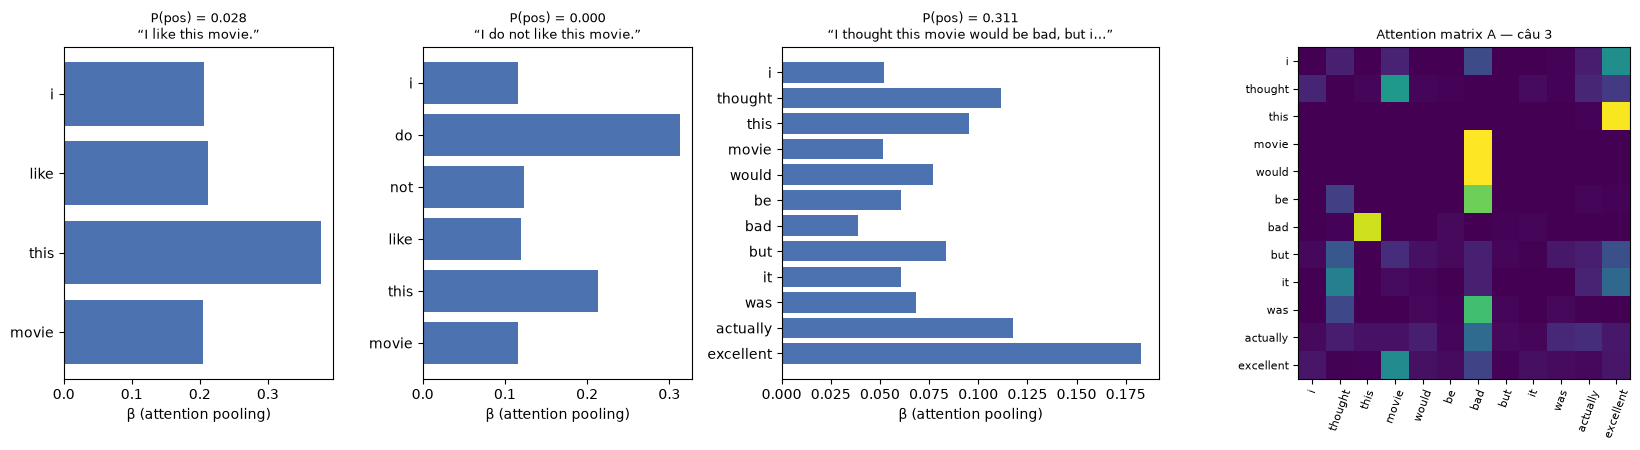

In [13]:
model_att = store["Self-Attention"]["model"]
@torch.no_grad()
def occlusion(ids, extra_masks=None):
    """Hàng 0 = review đầy đủ; hàng 1..L = bỏ từng token; extra_masks: các mask tùy chọn thêm vào cuối."""
    L = len(ids)
    masks = [torch.ones(L, dtype=torch.bool)] + [torch.arange(L) != t for t in range(L)] + (extra_masks or [])
    M = torch.stack(masks)
    X = torch.tensor(ids)[None].repeat(len(M), 1)
    logit, A, beta = model_att(X.to(device), mask=M.to(device), return_attn=True)
    p = torch.sigmoid(logit).cpu().numpy()
    return p[0], p[0] - p[1:L + 1], beta[0].cpu().numpy(), p[L + 1:]

vec = TfidfVectorizer(min_df=2, sublinear_tf=True)
lr = LogisticRegression(C=1.0, max_iter=2000).fit(vec.fit_transform(" ".join(t) for t in tok["train"]), y["train"])
vocab_lr = vec.get_feature_names_out(); coef = dict(zip(vocab_lr, lr.coef_[0]))
lr_prob = lambda texts: lr.predict_proba(vec.transform([" ".join(tokenize(t)) for t in texts]))[:, 1]
print("TF-IDF + LR (đối chứng): test accuracy =", round(accuracy_score(y["test"], lr_prob(test_df.text) > 0.5), 4))
print("Hệ số LR của một số từ:", {w: round(coef[w], 2) for w in ("like", "this", "movie", "film", "not", "good", "bad", "excellent", "but", "actually")})
APP = ["I like this movie.",
       "I do not like this movie.",
       "I thought this movie would be bad, but it was actually excellent.",
       "The movie was extremely long and the acting was sometimes boring, but the final scene was absolutely fantastic.",
       "This movie is not bad at all.",
       "Not good."]
app_rows = []
for text in APP:
    toks, A, beta, p = model_attention("Self-Attention", text)
    top = np.argsort(-beta)[:3]
    _, dP, _, _ = occlusion(encode(tokenize(text)))
    topo = np.argsort(-np.abs(dP))[:3]
    app_rows.append({"text": text, "prediction": "Positive" if p > 0.5 else "Negative", "P(pos) Self-Attention": p,
                     "P(pos) LSTM": prob_of("LSTM", [text])[0], "P(pos) +pos emb.": prob_of("Self-Attention + positional emb.", [text])[0],
                     "P(pos) pooling trên H": prob_of("Self-Attention (pooling trên H)", [text])[0], "P(pos) TF-IDF LR": lr_prob([text])[0],
                     "top-3 β": ", ".join(f"{toks[i]} {beta[i]:.2f}" for i in top),
                     "top-3 |ΔP| khi bỏ token (ΔP = P gốc − P bỏ)": ", ".join(f"{toks[i]} {dP[i]:+.3f}" for i in topo)})
    log("application", text, "P(pos) Self-Attention", p); log("application", text, "P(pos) LSTM", app_rows[-1]["P(pos) LSTM"])
app_df = pd.DataFrame(app_rows)
display(app_df.round(3))
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.4, 1.6]})
for a_, text in zip(ax[:3], APP[:3]):
    toks, A, beta, p = model_attention("Self-Attention", text)
    a_.barh(range(len(toks)), beta, color="#4c72b0"); a_.set_yticks(range(len(toks)), toks); a_.invert_yaxis()
    a_.set_title(f"P(pos) = {p:.3f}\n“{text[:40]}{'…' if len(text) > 40 else ''}”", fontsize=9); a_.set_xlabel("β (attention pooling)")
toks, A, beta, p = model_attention("Self-Attention", APP[2])
ax[3].imshow(A, cmap="viridis", vmin=0, vmax=1); ax[3].set_xticks(range(len(toks)), toks, rotation=70, fontsize=8); ax[3].set_yticks(range(len(toks)), toks, fontsize=8)
ax[3].set_title("Attention matrix A — câu 3", fontsize=9)
plt.tight_layout(); plt.savefig("images/application_attention.png", dpi=150); plt.show()

## Error analysis — Self-Attention trên IMDb test
Với mỗi review: top-5 token theo β và **occlusion**: bỏ (mask) từng token, đo P(pos) thay đổi bao nhiêu (ΔP = P(gốc) − P(bỏ token)). Nếu token được attention cao thật sự quyết định prediction thì ΔP của nó phải lớn — đây là cách kiểm chứng giả thuyết "attention nhìn vào đâu thì model dựa vào đó".

In [14]:
ea = test_df[["text", "label"]].copy()
ea["P(pos)"] = store["Self-Attention"]["prob"]; ea["P(pos) LSTM"] = store["LSTM"]["prob"]
ea["pred"] = (ea["P(pos)"] > 0.5).astype(int); ea["length"] = [len(t) for t in tok["test"]]
ea["truncated"] = ea.length > MAX_LEN
cm = confusion_matrix(ea.label, ea.pred)
print("Confusion matrix Self-Attention (hàng = thật neg/pos, cột = dự đoán neg/pos):\n", cm)
print("Accuracy theo độ dài:", ea.groupby(pd.cut(ea.length, [0, 100, 200, 400, 3000]))[["pred", "label"]].apply(lambda d: (d.pred == d.label).mean()).round(4).to_dict())
wrong = ea[ea.pred != ea.label]
print(f"Lỗi: {len(wrong)} | tỉ lệ lỗi là review bị cắt (>200 token): {wrong.truncated.mean():.1%} (toàn test: {ea.truncated.mean():.1%}) | "
      f"LSTM đoán đúng {((wrong['P(pos) LSTM'] > 0.5) == wrong.label).mean():.1%} số lỗi này")

def explain(i, k=5):
    ids = encode(tok["test"][i]); p, dP, beta, _ = occlusion(ids)
    toks = [itos[j] for j in ids]; top = np.argsort(-beta)[:k]; topocc = np.argsort(-np.abs(dP))[:k]
    return {"idx": i, "true": ["neg", "pos"][ea.label[i]], "pred": ["neg", "pos"][ea.pred[i]], "P(pos)": round(p, 3), "len": ea.length[i],
            "top-5 β (ΔP khi bỏ)": ", ".join(f"{toks[t]} {beta[t]:.2f} ({dP[t]:+.2f})" for t in top),
            "top-5 theo |ΔP|": ", ".join(f"{toks[t]} {dP[t]:+.2f}" for t in topocc),
            "text": ea.text[i].replace("<br />", " ")[:280]}
correct_ids = list(ea[ea.pred == ea.label].sample(3, random_state=7).index)
wrong_conf = list(wrong.assign(m=(wrong["P(pos)"] - 0.5).abs()).sort_values("m", ascending=False).index[:3])
wrong_rand = list(wrong.sample(3, random_state=7).index)
print("\nĐÚNG (ngẫu nhiên):"); display(pd.DataFrame([explain(i) for i in correct_ids]))
print("SAI — tự tin nhất:"); display(pd.DataFrame([explain(i) for i in wrong_conf]))
print("SAI — ngẫu nhiên:"); display(pd.DataFrame([explain(i) for i in wrong_rand]))

Confusion matrix Self-Attention (hàng = thật neg/pos, cột = dự đoán neg/pos):
 [[11098  1402]
 [ 2720  9780]]
Accuracy theo độ dài: {Interval(0, 100, closed='right'): 0.8641, Interval(100, 200, closed='right'): 0.858, Interval(200, 400, closed='right'): 0.8174, Interval(400, 3000, closed='right'): 0.759}
Lỗi: 4122 | tỉ lệ lỗi là review bị cắt (>200 token): 49.1% (toàn test: 40.3%) | LSTM đoán đúng 35.1% số lỗi này

ĐÚNG (ngẫu nhiên):


,idx,true,pred,P(pos),len,top-5 β (ΔP khi bỏ),top-5 theo |ΔP|,text
0,7323,neg,neg,0.002,230,"horrible 0.02 (-0.00), horrible 0.02 (-0.00), worst 0.02 (-0.00), ridiculous 0.02 (-0.00), from 0.01 (+0.00)","worst -0.00, horrible -0.00, horrible -0.00, attempt -0.00, attempt -0.00",The movie is being televised as I write. I simply forgot how horrible an experience I had watching it in the cinema. The whole idea of the movie is flawed. The fact that intelligent Europeans an...
1,175,neg,neg,0.020,128,"disappointing 0.04 (-0.03), bite 0.02 (-0.01), acting 0.02 (-0.00), snow 0.02 (-0.00), reworking 0.02 (+0.00)","disappointing -0.03, bite -0.01, money -0.01, human +0.01, less -0.01","The film had it moments, but was disappointing in my eyes anyway. It was a reworking of Trespass (Walter Hill) and so The Treasure Of the Sierra Madre, with less tension, bite and human emotion. T..."
2,1015,neg,neg,0.030,188,"worst 0.02 (-0.06), reason 0.02 (-0.01), topless 0.01 (-0.01), hand 0.01 (+0.00), slapped 0.01 (-0.01)","worst -0.06, topless -0.01, gas +0.01, bad -0.01, amazing +0.01","A 10 year old kid fed up with his parents arguing decides to hot wire a car and go on a surreal journey across America to find Motorama cards, which is a gas station card game, that if he can find..."


SAI — tự tin nhất:


,idx,true,pred,P(pos),len,top-5 β (ΔP khi bỏ),top-5 theo |ΔP|,text
0,8658,neg,pos,1.000,8,"suspenseful 0.17 (-0.00), subtle 0.15 (+0.00), more 0.12 (+0.00), more 0.12 (+0.00), more 0.12 (+0.00)","subtle +0.00, more +0.00, more +0.00, more +0.00, much -0.00","More suspenseful, more subtle, much, much more disturbing...."
1,11323,neg,pos,0.999,39,"from 0.07 (-0.00), she 0.04 (-0.00), fantastic 0.04 (+0.00), girl's 0.04 (-0.00), but 0.04 (-0.00)","fantastic +0.00, well +0.00, well +0.00, well +0.00, and +0.00","Nice movie and Nicholle Tom does a fantastic job playing the ""guy in the girl's body"", she really does it well. A sort of teen version of many other movies, but well done. Well casted, from ""Mat..."
2,4118,neg,pos,0.999,61,"case 0.04 (-0.00), actor 0.04 (-0.00), which 0.03 (-0.00), role 0.03 (-0.00), screenplay 0.03 (-0.00)","great +0.00, masterpiece +0.00, kung +0.00, actor -0.00, screenplay -0.00",This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in ...


SAI — ngẫu nhiên:


,idx,true,pred,P(pos),len,top-5 β (ΔP khi bỏ),top-5 theo |ΔP|,text
0,15270,pos,neg,0.184,320,"becoming 0.02 (-0.07), thoroughly 0.02 (+0.03), clear 0.01 (-0.01), console 0.01 (+0.01), answer 0.01 (-0.00)","becoming -0.07, desperately -0.05, neglected +0.04, why -0.04, monster -0.03","i went to watch this film with my family who were expecting a neatly conclusive story like ''mr.& mrs.iyer''.and they returned home thoroughly disappointed.so,this is a warning to all ''conclusive..."
1,14725,pos,neg,0.476,343,"from 0.01 (+0.00), from 0.01 (+0.00), quiet 0.01 (+0.06), adapting 0.01 (+0.01), culture 0.01 (+0.05)","not -0.06, not -0.06, quiet +0.06, trying -0.06, less -0.05","The movie ""Everything is Illuminated"" comes from first-time writer-director Liev Schreiber, adapting Jonathan Safran Foer's first novel. The book was ambitious and sprawling, its magical-realist e..."
2,12990,pos,neg,0.219,411,"people 0.01 (+0.00), terribly 0.01 (-0.06), loosely 0.01 (-0.06), what's 0.01 (-0.03), outside 0.01 (+0.01)","terribly -0.06, loosely -0.06, shows +0.06, word -0.04, read -0.04","Note: After writing this review I see that this listing is indeed about the TV series and not the original film. My mistake. I thought IMDb for a database for movies, not TV shows. But since most ..."


### Kiểm chứng định lượng: attention cao có phải là token quyết định prediction không?
300 review test ngẫu nhiên. (1) Spearman ρ giữa β<sub>t</sub> và |ΔP<sub>t</sub>| trong từng review. (2) Bỏ cùng lúc 5 token có β cao nhất / 5 token ngẫu nhiên / 5 token có β thấp nhất. (3) "Từ mang sentiment" = từ có |hệ số| lớn trong TF-IDF + Logistic Regression (đại diện cho các từ mà người đọc cho là quan trọng): phần attention β rơi vào các từ này so với tỉ lệ các từ này trong review.

In [15]:
order_c = np.argsort(lr.coef_[0])
LEX = {f"|hệ số LR| ≥ {th}": {w for w, c in coef.items() if abs(c) >= th} for th in (2, 4)}
print("Số từ:", {k: len(v) for k, v in LEX.items()}, "| mạnh nhất:", list(vocab_lr[order_c[-6:]]), list(vocab_lr[order_c[:6]]))

rs = np.random.RandomState(SEED)
sample = rs.choice(len(test_df), 300, replace=False)
faith = []
for i in sample:
    ids = encode(tok["test"][i]); L = len(ids)
    if L < 10:
        continue
    # mask bỏ 5 token β cao nhất / 5 ngẫu nhiên (3 lần) / 5 β thấp nhất
    p0, dP, beta, _ = occlusion(ids)
    top5, low5 = np.argsort(-beta)[:5], np.argsort(beta)[:5]
    def drop(idx):
        m = torch.ones(L, dtype=torch.bool); m[torch.as_tensor(idx)] = False; return m
    rand_sets = [rs.choice(L, 5, replace=False) for _ in range(3)]
    _, _, _, p_extra = occlusion(ids, [drop(top5), drop(low5)] + [drop(r) for r in rand_sets])
    toks = [itos[j] for j in ids]
    lex_stats = {}
    for lname, lset in LEX.items():
        is_lex = np.array([w in lset for w in toks])
        lex_stats[f"β trên từ {lname}"] = beta[is_lex].sum(); lex_stats[f"tỉ lệ token là từ {lname}"] = is_lex.mean()
    faith.append({**lex_stats, "rho": spearmanr(beta, np.abs(dP)).correlation, "top5": abs(p0 - p_extra[0]), "low5": abs(p0 - p_extra[1]),
                  "rand5": np.mean([abs(p0 - q) for q in p_extra[2:]]),
                  "flip top5": (p0 > 0.5) != (p_extra[0] > 0.5), "flip rand5": np.mean([(p0 > 0.5) != (q > 0.5) for q in p_extra[2:]]),
                  "top1 β = top1 |ΔP|": np.argmax(beta) == np.argmax(np.abs(dP))})
faith = pd.DataFrame(faith)
summary = {"reviews": len(faith), "Spearman ρ(β, |ΔP|) trung bình": faith.rho.mean(), "ρ trung vị": faith.rho.median(),
           "|ΔP| bỏ 5 token β cao nhất": faith.top5.mean(), "|ΔP| bỏ 5 token ngẫu nhiên": faith.rand5.mean(), "|ΔP| bỏ 5 token β thấp nhất": faith.low5.mean(),
           "% đổi nhãn (bỏ top-5 β)": faith["flip top5"].mean(), "% đổi nhãn (bỏ 5 ngẫu nhiên)": faith["flip rand5"].mean(),
           **{k: faith[k].mean() for k in faith.columns if k.startswith(("β trên", "tỉ lệ token"))},
           "% review: token β cao nhất = token |ΔP| lớn nhất": faith["top1 β = top1 |ΔP|"].mean()}
display(pd.Series(summary).round(4).to_frame("giá trị"))
for k, v in summary.items():
    log("attention faithfulness (300 test reviews)", "Self-Attention", k, v)

Số từ: {'|hệ số LR| ≥ 2': 116, '|hệ số LR| ≥ 4': 15} | mạnh nhất: ['amazing', 'wonderful', 'perfect', 'best', 'excellent', 'great'] ['worst', 'bad', 'awful', 'waste', 'boring', 'poor']


,giá trị
reviews,300.0000
"Spearman ρ(β, |ΔP|) trung bình",0.3551
ρ trung vị,0.3558
|ΔP| bỏ 5 token β cao nhất,0.1081
|ΔP| bỏ 5 token ngẫu nhiên,0.0232
|ΔP| bỏ 5 token β thấp nhất,0.0575
% đổi nhãn (bỏ top-5 β),0.1033
% đổi nhãn (bỏ 5 ngẫu nhiên),0.0178
β trên từ |hệ số LR| ≥ 2,0.1152
tỉ lệ token là từ |hệ số LR| ≥ 2,0.1124


In [16]:
pd.DataFrame(results).to_csv("results.csv", index=False)
print("Đã ghi results.csv:", len(results), "dòng")

Đã ghi results.csv: 166 dòng
